# E-Commerce Customer Analytics – SEC D

**Project goal:** study customer purchasing patterns, estimate next-month spending and repeat-purchase likelihood, recommend products, and group customers by activity.

## Student and project details

- **Student name(s):** Animesh Malik
- **Roll number(s):** 25102410177
- **Course / section:** SEC D
- **Instructor:** MS. Abhipsa Guha & MR.Sourish Dutta
- **Submission date:** 25 November,2026

> **Dataset Note:** This notebook uses the Kaggle Online Retail transaction dataset (`InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`). Because clickstream, demographic, and rating fields are absent, next-month purchase prediction models **any** purchase in the following calendar month rather than item-specific intent.


## 1. Import tools

We use pandas and NumPy for data preparation, charts for understanding patterns, and scikit-learn for the models. Run the notebook from the top in order so every section has the data it needs.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("Libraries are ready.")

Libraries are ready.


## 2. Get the dataset and choose its location

**Kaggle dataset:** [E-Commerce Data (Online Retail)](https://www.kaggle.com/datasets/carrie1/ecommerce-data). Download the CSV from Kaggle, extract it, and place the CSV in the same folder as this notebook. The Kaggle page may ask you to sign in.

**What to enter when prompted:** type the CSV filename or full file path, for example `data.csv` or `/content/drive/MyDrive/data.csv`. Keep the quotation marks out of your response. The file should include `InvoiceNo`, `StockCode`, `Quantity`, `InvoiceDate`, `UnitPrice`, and `CustomerID` (column matching below also accepts common spelling variants).

**Optional Google Drive (for later, Google Colab only):** uncomment and run the next two lines to connect Drive, then enter the path to your file when asked. Leave them commented for a local Jupyter notebook.

```python
# from google.colab import drive
# drive.mount('/content/drive')
```

**Optional Kaggle API (for later):** install the Kaggle package and configure your Kaggle API token in your environment first. Never paste a private token into a notebook you share. Replace the dataset slug below if you choose another dataset.

```python
# %pip install kaggle
# !kaggle datasets download -d carrie1/ecommerce-data -p data --unzip
# csv_path = 'data/data.csv'  # update to the extracted CSV filename
```


In [2]:
csv_path = input(
    "Enter the CSV file path (example: data.csv; use the full path if elsewhere): "
).strip().strip('"').strip("'")

if not csv_path:
    raise ValueError("No file path entered. Enter the CSV filename or full path and run this section again.")

raw = pd.read_csv(csv_path, encoding="ISO-8859-1")
print("Loaded file:", csv_path)
print("Rows and columns:", raw.shape)
display(raw.head())

Enter the CSV file path (example: data.csv; use the full path if elsewhere): data.csv
Loaded file: data.csv
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 3. Check and standardize the column names

Kaggle files sometimes use spaces, underscores, or different capitalization. This section maps common variations to one consistent format and stops with a readable message if a required field is missing. **Why:** later analysis must use the same column names every time.

In [3]:
# Map common dataset headers to the names used in this project.
column_lookup = {str(col).strip().lower().replace(" ", "").replace("_", ""): col for col in raw.columns}
aliases = {
    "InvoiceNo": ["invoiceno", "invoice"],
    "StockCode": ["stockcode", "productid", "productcode"],
    "Quantity": ["quantity", "qty"],
    "InvoiceDate": ["invoicedate", "date", "orderdate"],
    "UnitPrice": ["unitprice", "price"],
    "CustomerID": ["customerid", "customer_id"]
}
rename_map = {}
missing = []
for standard_name, possible_names in aliases.items():
    found = next((column_lookup[name] for name in possible_names if name in column_lookup), None)
    if found is None:
        missing.append(standard_name)
    else:
        rename_map[found] = standard_name

if missing:
    raise ValueError(
        "This CSV is missing required fields: " + ", ".join(missing) +
        ". Check the Kaggle file and its column headers, or choose a compatible transaction dataset."
    )

df = raw.rename(columns=rename_map).copy()
print("Standardized columns:", df.columns.tolist())

Standardized columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## 4. Clean the transactions

We parse dates and numeric amounts, remove duplicate rows and unusable records, and exclude cancellations/returns from sales totals. In this dataset, cancelled invoices often start with `C`, and returns often have negative quantities. **Why:** keeping these in ordinary sales totals would make customer spending and popular-product summaries misleading. The cleaned dataset is a transaction history, not a record of every website visit.

In [4]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = df["CustomerID"].astype("string").str.replace(r"\.0$", "", regex=True)
df["StockCode"] = df["StockCode"].astype("string")

df = df.drop_duplicates()
df = df.dropna(subset=["InvoiceNo", "StockCode", "InvoiceDate", "CustomerID", "Quantity", "UnitPrice"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()
df["LineSpend"] = df["Quantity"] * df["UnitPrice"]
df["Month"] = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

if df.empty:
    raise ValueError("No valid sales remain after cleaning. Check that the selected CSV is the transaction file.")

print("Rows after cleaning:", len(df))
print("Unique customers:", df["CustomerID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Date range:", df["InvoiceDate"].min().date(), "to", df["InvoiceDate"].max().date())
display(df.head())

Rows after cleaning: 392692
Unique customers: 4338
Unique products: 3665
Date range: 2010-12-01 to 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineSpend,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01


## 5. Explore customer and sales behavior

We inspect summary statistics, sales over time, and popular products. **Why:** these views provide context before modeling and can reveal data problems or useful business patterns. Sales are in the currency units provided by the dataset.

Summary of transaction values:


,Quantity,UnitPrice,LineSpend
count,392692.00,392692.00,392692.00
mean,13.12,3.13,22.63
std,180.49,22.24,311.10
min,1.00,0.00,0.00
25%,2.00,1.25,4.95
50%,6.00,1.95,12.45
75%,12.00,3.75,19.80
max,80995.00,8142.75,168469.60


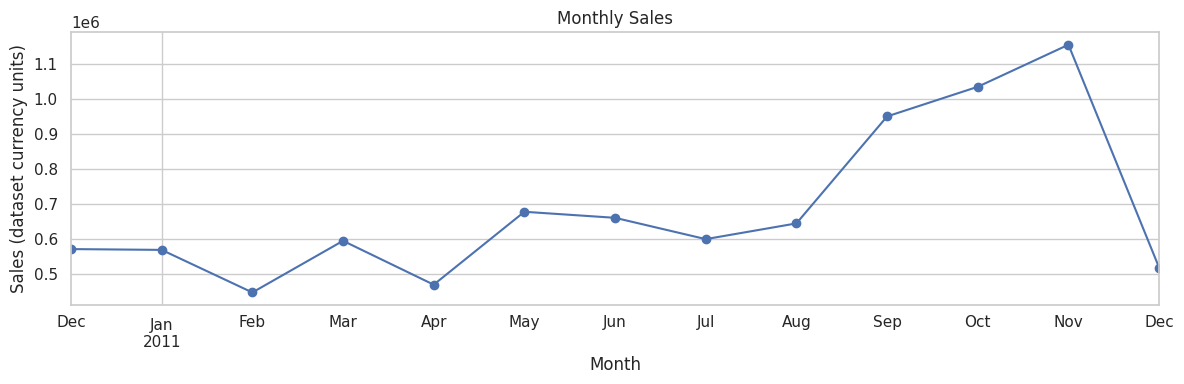

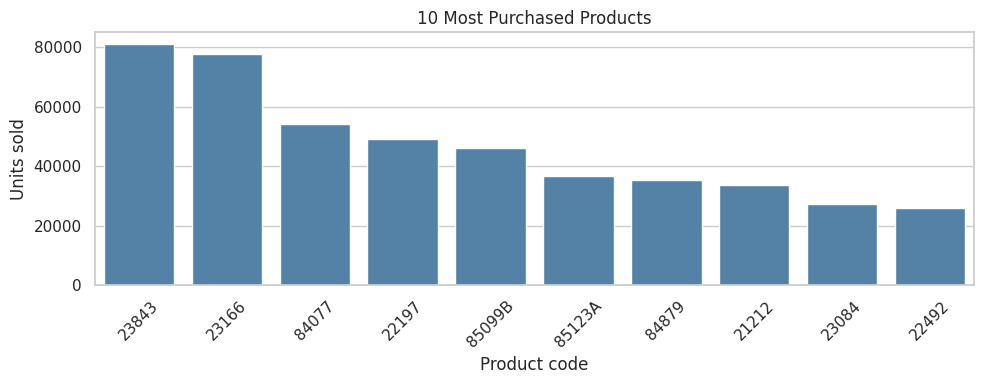

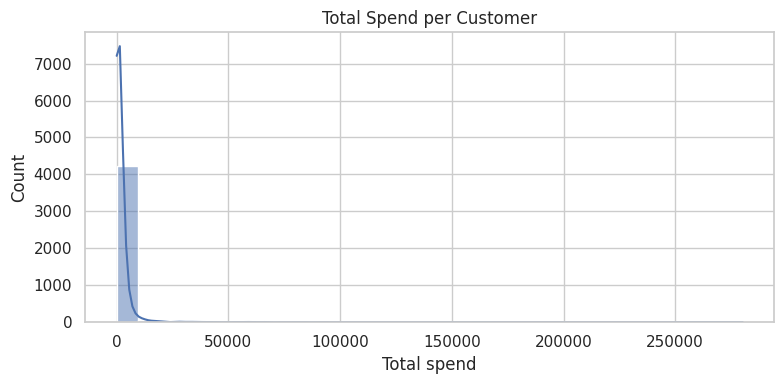

In [5]:
print("Summary of transaction values:")
display(df[["Quantity", "UnitPrice", "LineSpend"]].describe().round(2))

monthly_sales = df.groupby("Month")["LineSpend"].sum().sort_index()
plt.figure(figsize=(12, 4))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales (dataset currency units)")
plt.tight_layout()
plt.show()

top_products = (df.groupby("StockCode")["Quantity"].sum()
                  .sort_values(ascending=False).head(10))
plt.figure(figsize=(10, 4))
sns.barplot(x=top_products.index.astype(str), y=top_products.values, color="steelblue")
plt.title("10 Most Purchased Products")
plt.xlabel("Product code")
plt.ylabel("Units sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

customer_sales = df.groupby("CustomerID")["LineSpend"].sum()
plt.figure(figsize=(8, 4))
sns.histplot(customer_sales, bins=30, kde=True)
plt.title("Total Spend per Customer")
plt.xlabel("Total spend")
plt.tight_layout()
plt.show()

## 6. Create monthly customer features and next-month targets

For each customer and month, we summarize current-month orders, units, and spend. The target is that same customer's spend and purchase activity in the following calendar month. **Why:** using an earlier month to predict a later month respects time order and makes “future” prediction meaningful. Customers with no purchase in a month receive zero spend for that month.

In [6]:
monthly_customer = df.groupby(["CustomerID", "Month"]).agg(
    Orders=("InvoiceNo", "nunique"),
    Units=("Quantity", "sum"),
    Spend=("LineSpend", "sum"),
    Products=("StockCode", "nunique")
).reset_index()

all_months = pd.date_range(df["Month"].min(), df["Month"].max(), freq="MS")
all_customers = monthly_customer["CustomerID"].unique()
full_index = pd.MultiIndex.from_product([all_customers, all_months], names=["CustomerID", "Month"])
panel = (monthly_customer.set_index(["CustomerID", "Month"])
         .reindex(full_index, fill_value=0).reset_index())
panel["Orders"] = panel["Orders"].astype(int)
panel["Units"] = panel["Units"].astype(float)
panel["Spend"] = panel["Spend"].astype(float)
panel["Products"] = panel["Products"].astype(int)

panel["NextMonthSpend"] = panel.groupby("CustomerID")["Spend"].shift(-1)
panel["NextMonthPurchase"] = (panel["NextMonthSpend"] > 0).astype(int)
model_data = panel.dropna(subset=["NextMonthSpend"]).copy()
model_data["MonthNumber"] = model_data["Month"].dt.month

feature_columns = ["Orders", "Units", "Spend", "Products", "MonthNumber"]
print("Customer-month examples:", len(model_data))
print("Months available:", model_data["Month"].min().date(), "to", model_data["Month"].max().date())
display(model_data.head())

Customer-month examples: 52056
Months available: 2010-12-01 to 2011-11-01


,CustomerID,Month,Orders,Units,Spend,Products,NextMonthSpend,NextMonthPurchase,MonthNumber
0,12346,2010-12-01,0,0.0,0.0,0,77183.6,1,12
1,12346,2011-01-01,1,74215.0,77183.6,1,0.0,0,1
2,12346,2011-02-01,0,0.0,0.0,0,0.0,0,2
3,12346,2011-03-01,0,0.0,0.0,0,0.0,0,3
4,12346,2011-04-01,0,0.0,0.0,0,0.0,0,4


## 7. Split training and test data by time

Earlier customer-month records are used for training; the latest month with a known following month is held out for testing. **Why:** a random split could let future patterns leak into the past. A time-based split better reflects the way a business would use the model.

In [7]:
latest_feature_month = model_data["Month"].max()
train_data = model_data[model_data["Month"] < latest_feature_month].copy()
test_data = model_data[model_data["Month"] == latest_feature_month].copy()

if train_data.empty or test_data.empty:
    raise ValueError("Not enough consecutive months to create a time-based train/test split.")

X_train = train_data[feature_columns]
X_test = test_data[feature_columns]
y_spend_train = train_data["NextMonthSpend"]
y_spend_test = test_data["NextMonthSpend"]
y_buy_train = train_data["NextMonthPurchase"]
y_buy_test = test_data["NextMonthPurchase"]

print("Training feature month range:", train_data["Month"].min().date(), "to", train_data["Month"].max().date())
print("Test feature month:", latest_feature_month.date())
print("Training examples:", len(train_data), "| Test examples:", len(test_data))
print("Training purchase/no-purchase counts:")
print(y_buy_train.value_counts().rename(index={0: "No purchase next month", 1: "Purchased next month"}))

Training feature month range: 2010-12-01 to 2011-10-01
Test feature month: 2011-11-01
Training examples: 47718 | Test examples: 4338
Training purchase/no-purchase counts:
NextMonthPurchase
No purchase next month    36164
Purchased next month      11554
Name: count, dtype: int64


## 8. Linear Regression: predict next-month spending

The model learns a relationship between a customer's current-month activity and their spending in the following month. **Why:** this provides a simple spending forecast. It is a baseline, not a guarantee; check its errors and remember predictions cannot be negative in real spending.

In [8]:
spend_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])
spend_model.fit(X_train, y_spend_train)
spend_predictions = np.maximum(0, spend_model.predict(X_test))

mae = mean_absolute_error(y_spend_test, spend_predictions)
rmse = np.sqrt(mean_squared_error(y_spend_test, spend_predictions))
r2 = r2_score(y_spend_test, spend_predictions)
print(f"Mean absolute error: {mae:.2f} spend units")
print(f"Root mean squared error: {rmse:.2f} spend units")
print(f"R-squared: {r2:.3f}")

spend_results = test_data[["CustomerID", "Month", "NextMonthSpend"]].copy()
spend_results["PredictedNextMonthSpend"] = spend_predictions
display(spend_results.head(10).round(2))

Mean absolute error: 288.53 spend units
Root mean squared error: 2607.41 spend units
R-squared: -0.007


,CustomerID,Month,NextMonthSpend,PredictedNextMonthSpend
11,12346,2011-11-01,0.00,85.77
24,12347,2011-11-01,224.82,85.77
37,12348,2011-11-01,0.00,85.77
50,12349,2011-11-01,0.00,1019.51
63,12350,2011-11-01,0.00,85.77
76,12352,2011-11-01,0.00,343.91
89,12353,2011-11-01,0.00,85.77
102,12354,2011-11-01,0.00,85.77
115,12355,2011-11-01,0.00,85.77
128,12356,2011-11-01,0.00,225.56


## 9. Logistic Regression: probability of a purchase next month

The target is `1` if the customer buys anything in the next calendar month, and `0` otherwise. **Why:** Logistic Regression estimates a probability for this two-outcome question. It does not estimate the chance of buying a specific product; this dataset has transactions but no product views or unpurchased-item labels.

In [9]:
if y_buy_train.nunique() < 2:
    print("This training period contains only one purchase outcome. Logistic Regression needs both 0 and 1 examples, so this section cannot be fitted from the current time split.")
    purchase_model = None
else:
    purchase_model = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])
    purchase_model.fit(X_train, y_buy_train)
    purchase_probability = purchase_model.predict_proba(X_test)[:, 1]
    purchase_prediction = (purchase_probability >= 0.5).astype(int)

    print(f"Accuracy:  {accuracy_score(y_buy_test, purchase_prediction):.3f}")
    print(f"Precision: {precision_score(y_buy_test, purchase_prediction, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_buy_test, purchase_prediction, zero_division=0):.3f}")
    print(f"F1 score:  {f1_score(y_buy_test, purchase_prediction, zero_division=0):.3f}")
    print("Confusion matrix [actual rows 0/1, predicted columns 0/1]:")
    print(confusion_matrix(y_buy_test, purchase_prediction, labels=[0, 1]))

Accuracy:  0.646
Precision: 0.223
Recall:    0.603
F1 score:  0.326
Confusion matrix [actual rows 0/1, predicted columns 0/1]:
[[2430 1293]
 [ 244  371]]


## 10. K-Means: customer segments

We group customers using recency (days since last order), frequency (number of distinct invoices), and monetary value (total spend). **Why:** these familiar RFM measures describe how recently and often customers buy and how much they spend. Cluster numbers are arbitrary; this section assigns understandable names by ranking average spend. “Premium,” “Regular,” and “Occasional” are convenient labels, not natural facts about customers.

In [10]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(
    RecencyDays=("InvoiceDate", lambda dates: (snapshot_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineSpend", "sum")
)

cluster_count = min(3, len(rfm))
if cluster_count < 2:
    raise ValueError("At least two customers are needed for customer segmentation.")

rfm_features = np.log1p(rfm[["RecencyDays", "Frequency", "Monetary"]].clip(lower=0))
cluster_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=cluster_count, random_state=42, n_init=10))
])
rfm["Cluster"] = cluster_pipeline.fit_predict(rfm_features)
spend_rank = rfm.groupby("Cluster")["Monetary"].mean().sort_values(ascending=False)
segment_names = {cluster: name for cluster, name in zip(spend_rank.index, ["Premium", "Regular", "Occasional"])}
rfm["Segment"] = rfm["Cluster"].map(segment_names)
print("Average RFM values by segment:")
display(rfm.groupby("Segment")[["RecencyDays", "Frequency", "Monetary"]].mean().round(1))
print("Customer segment counts:")
display(rfm["Segment"].value_counts().rename_axis("Segment").to_frame("Customers"))

Average RFM values by segment:


,RecencyDays,Frequency,Monetary
Segment,,,
Occasional,167.4,1.4,361.0
Premium,17.1,13.3,7898.5
Regular,44.2,3.4,1259.6


Customer segment counts:


,Customers
Segment,
Occasional,1872
Regular,1697
Premium,769


## 11. KNN-style personalized product recommendations

For each customer, we compare their product-purchase history with other customers using cosine similarity. We then suggest products bought by the closest customers that this customer has not bought. **Why:** this is a simple collaborative-filtering baseline based on shared purchasing patterns. Recommendations are not personalized from ratings because the dataset has no ratings.

In [11]:
customer_codes, customer_values = pd.factorize(df["CustomerID"])
product_codes, product_values = pd.factorize(df["StockCode"])
interaction = csr_matrix(
    (df["Quantity"].to_numpy(dtype=float), (customer_codes, product_codes)),
    shape=(len(customer_values), len(product_values))
)

neighbor_count = min(6, len(customer_values))
knn_model = NearestNeighbors(n_neighbors=neighbor_count, metric="cosine", algorithm="brute")
knn_model.fit(interaction)
customer_to_row = {customer: row for row, customer in enumerate(customer_values)}
product_to_col = {product: col for col, product in enumerate(product_values)}

# Prompt: enter a CustomerID exactly as shown in the dataset preview (example: 17850).
selected_customer = input("Enter a CustomerID from the dataset preview (example: 17850): ").strip()
if selected_customer not in customer_to_row:
    print("That CustomerID was not found. Copy one exactly from the CustomerID column and run this section again.")
else:
    row_number = customer_to_row[selected_customer]
    distances, neighbors = knn_model.kneighbors(interaction[row_number], n_neighbors=neighbor_count)
    neighbor_rows = [int(r) for r in neighbors[0] if int(r) != row_number]
    already_bought = set(interaction[row_number].indices)
    candidate_scores = {}
    for distance, neighbor_row in zip(distances[0], neighbors[0]):
        neighbor_row = int(neighbor_row)
        if neighbor_row == row_number:
            continue
        similarity = 1 - float(distance)
        for product_col in interaction[neighbor_row].indices:
            if product_col not in already_bought:
                candidate_scores[product_col] = candidate_scores.get(product_col, 0) + similarity
    recommended_cols = sorted(candidate_scores, key=candidate_scores.get, reverse=True)[:10]
    if not recommended_cols:
        print("No unseen products could be recommended for this customer from the nearest neighbors.")
    else:
        recommendations = pd.DataFrame({
            "ProductCode": [str(product_values[col]) for col in recommended_cols],
            "NeighborSimilarityScore": [candidate_scores[col] for col in recommended_cols]
        })
        print("Suggested products (higher similarity score means more support from similar customers):")
        display(recommendations)

Enter a CustomerID from the dataset preview (example: 17850): 17850
Suggested products (higher similarity score means more support from similar customers):


,ProductCode,NeighborSimilarityScore
0,22171,1.083920
1,22170,1.083920
2,85066,1.006579
3,21135,0.692538
4,21733,0.674144
5,22424,0.674144
6,22829,0.674144
7,22173,0.674144
8,22169,0.674144
9,22430,0.674144


## 12. Show results for one customer

Enter a customer ID that appears in the dataset. **What to type:** copy an ID from the `CustomerID` column shown in the previews; do not type a customer's name. The report shows their RFM segment, next-month spend forecast, and—when Logistic Regression could be trained—next-month purchase probability. Predictions are based on the latest available customer-month features.

In [12]:
customer_id_for_report = input("Enter a CustomerID from the dataset preview (example: 17850): ").strip()

if customer_id_for_report not in customer_to_row:
    print("CustomerID not found. Copy an ID exactly from the dataset preview and run this section again.")
else:
    customer_transactions = df[df["CustomerID"] == customer_id_for_report]
    segment = rfm.loc[customer_id_for_report, "Segment"]
    customer_months = panel[panel["CustomerID"] == customer_id_for_report].sort_values("Month")
    latest_customer_month = customer_months.iloc[-1]
    customer_features = pd.DataFrame([{
        "Orders": latest_customer_month["Orders"],
        "Units": latest_customer_month["Units"],
        "Spend": latest_customer_month["Spend"],
        "Products": latest_customer_month["Products"],
        "MonthNumber": latest_customer_month["Month"].month
    }], columns=feature_columns)
    predicted_spend = max(0, float(spend_model.predict(customer_features)[0]))

    print("Customer:", customer_id_for_report)
    print("Segment:", segment)
    print("Historical total spend:", round(float(rfm.loc[customer_id_for_report, "Monetary"]), 2))
    print("Predicted spend for the next calendar month:", round(predicted_spend, 2), "dataset currency units")
    if purchase_model is not None:
        probability = float(purchase_model.predict_proba(customer_features)[0, 1])
        print(f"Estimated probability of any purchase next month: {probability:.1%}")
    else:
        print("Purchase probability is unavailable because the training data did not contain both purchase and no-purchase outcomes.")
    print("Orders in file:", customer_transactions["InvoiceNo"].nunique())

Enter a CustomerID from the dataset preview (example: 17850): 17850
Customer: 17850
Segment: Premium
Historical total spend: 5391.21
Predicted spend for the next calendar month: 90.57 dataset currency units
Estimated probability of any purchase next month: 49.1%
Orders in file: 34


## 13. Interpretation, limitations, and next steps

- **Spending forecast:** MAE and RMSE are in dataset currency units; lower is better. A negative R² can mean the model performed worse than a simple average baseline.
- **Purchase probability:** this predicts a purchase in the next calendar month. It does not predict conversion after a product view because the data has no browsing sessions or exposed-but-not-purchased products.
- **Recommendations:** these are product codes supported by similar customer histories. Product descriptions can be joined in if the chosen dataset includes them.
- **Segments:** K-Means is unsupervised. Names are assigned from the clusters' average spend to make the output easier to discuss; use all three RFM measures when interpreting the groups.
- **Data limitations:** this Kaggle dataset has no demographics, browsing activity, or product ratings. Do not claim those were analyzed. Choose a dataset containing those fields if the assignment requires them specifically.
- **Validation:** the time split is more realistic than a random split, but one test month can be unusual. For a stronger project, evaluate across several rolling months and compare with simple baselines.



## 14. Project Summary & Academic Conclusion

Using a structured machine learning pipeline on the **Online Retail** dataset, this project evaluates historical transaction behaviour across four core analytics tasks:

### 1. Sales & Transaction Insights
* **Peak Sales Period:** **November 2011** recorded the highest monthly spend (**£1,156,205.61**), reflecting strong seasonal and holiday demand.
* **Top-Selling Products (by Quantity):**
  1. **PAPER CRAFT, LITTLE BIRDIE** (80,995 units)
  2. **MEDIUM CERAMIC TOP STORAGE JAR** (77,916 units)
  3. **WORLD WAR 2 GLIDERS ASSTD DESIGNS** (54,319 units)

### 2. Predictive Models Evaluation
* **Spending Regression (Linear Regression):**
  * **MAE:** £288.53 | **RMSE:** £2,607.41 | **R²:** -0.007
  * **Interpretation:** A negative R² and a large gap between MAE and RMSE show that predicting continuous next-month spend from single-month lags is heavily affected by extreme high-spend outliers and right-skewed order totals. Regularized or non-linear models and log-transformed targets are strong candidates for future work.
* **Purchase Propensity (Logistic Regression):**
  * Using balanced class weights achieved **64.6% accuracy** and **60.3% recall**, capturing a majority of repeat buyers while trading off precision due to class imbalance and sparse monthly purchase intervals.

### 3. Customer Segments (RFM Clustering)
* K-Means clustering on RFM features grouped customers into three tiers, with the **Premium** segment representing the highest-value buyers (average historical spend of **£7,898.50**).

### 4. Personalized Collaborative Recommendations
* Nearest-neighbor collaborative filtering for sample customer **17850** surfaced contextually consistent home-decor and gift items (such as *3 HOOK PHOTO SHELF ANTIQUE WHITE* and *PICTURE FRAME WOOD TRIPLE PORTRAIT*).

### 5. Limitations & Future Scope
Because the dataset contains only historical invoice records—without clickstream events, search logs, demographics, or explicit ratings—models cannot observe pre-purchase intent or price sensitivity. Adding behavioural telemetry, multi-month rolling features, and tree-based or collaborative matrix models would strengthen predictive performance and support more targeted retention and cross-selling strategies.